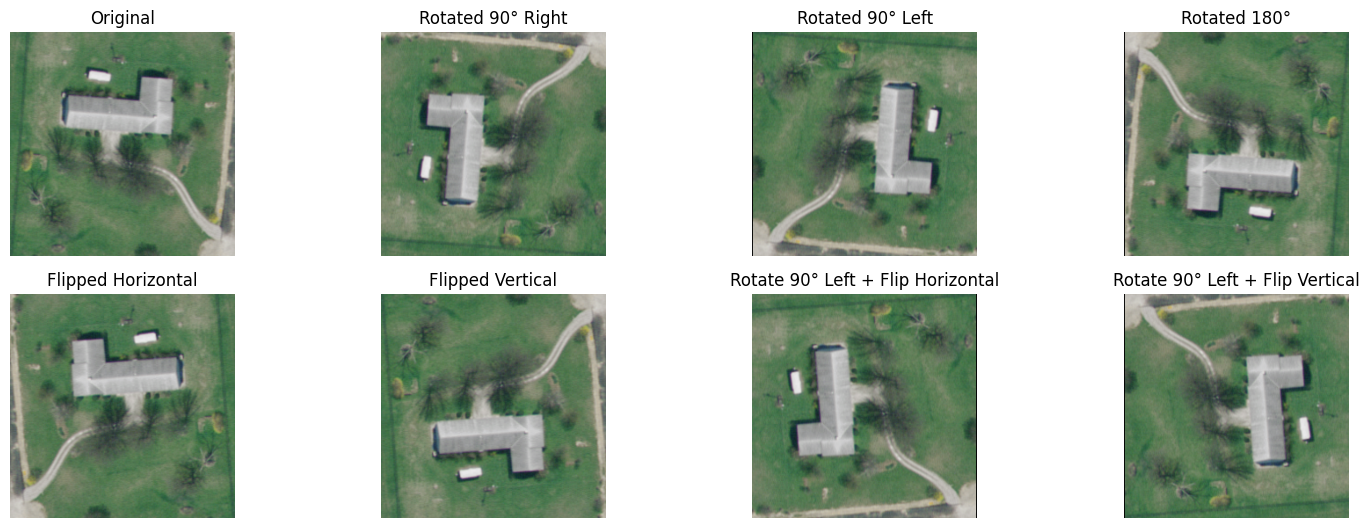

In [5]:
import cv2
import matplotlib.pyplot as plt

# Load the image
image_path = "UCMerced_LandUse/train/sparseresidential/sparseresidential58.tif" 
image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Define augmentation functions
def rotate_image(image, angle):
    (h, w) = image.shape[:2]
    center = (w // 2, h // 2)
    matrix = cv2.getRotationMatrix2D(center, angle, 1.0)
    rotated = cv2.warpAffine(image, matrix, (w, h))
    return rotated

# Apply augmentations
augmentations = {
    "Original": image,
    "Rotated 90° Right": rotate_image(image, 90),
    "Rotated 90° Left": rotate_image(image, -90),
    "Rotated 180°": rotate_image(image, 180),
    "Flipped Horizontal": cv2.flip(image, 1),
    "Flipped Vertical": cv2.flip(image, 0),
    "Rotate 90° Left + Flip Horizontal": cv2.flip(rotate_image(image, -90), 1),
    "Rotate 90° Left + Flip Vertical": cv2.flip(rotate_image(image, -90), 0),
}

# Plot the results
plt.figure(figsize=(15, 8))
for i, (title, aug_image) in enumerate(augmentations.items(), 1):
    plt.subplot(3, 4, i)
    plt.imshow(aug_image)
    plt.title(title)
    plt.axis("off")
plt.tight_layout()
plt.show()


In [8]:
import os
import cv2

# Define augmentation functions
def rotate_image(image, angle):
    (h, w) = image.shape[:2]
    center = (w // 2, h // 2)
    matrix = cv2.getRotationMatrix2D(center, angle, 1.0)
    rotated = cv2.warpAffine(image, matrix, (w, h))
    return rotated

# Define augmentations
def apply_augmentations(image):
    augmentations = {
        "original": image,
        "rotated_90_right": rotate_image(image, 90),
        "rotated_90_left": rotate_image(image, -90),
        "rotated_180": rotate_image(image, 180),
        "flipped_horizontal": cv2.flip(image, 1),
        "flipped_vertical": cv2.flip(image, 0),
        "rotated_90_left_flipped_horizontal": cv2.flip(rotate_image(image, -90), 1),
        "rotated_90_left_flipped_vertical": cv2.flip(rotate_image(image, -90), 0),
    }
    return augmentations

# Paths
input_folder = "UCMerced_LandUse_augmented/train"  
output_folder = "UCMerced_LandUse_augmented/train_augmented"

# Create output folder structure
os.makedirs(output_folder, exist_ok=True)
for subfolder in os.listdir(input_folder):
    subfolder_path = os.path.join(input_folder, subfolder)
    if os.path.isdir(subfolder_path):
        os.makedirs(os.path.join(output_folder, subfolder), exist_ok=True)

# Process each image in the dataset
for subfolder in os.listdir(input_folder):
    subfolder_path = os.path.join(input_folder, subfolder)
    if os.path.isdir(subfolder_path):
        output_subfolder = os.path.join(output_folder, subfolder)
        for image_name in os.listdir(subfolder_path):
            image_path = os.path.join(subfolder_path, image_name)
            if os.path.isfile(image_path):
                # Read and augment the image
                image = cv2.imread(image_path)
                augmentations = apply_augmentations(image)

                # Save augmented images
                for aug_name, aug_image in augmentations.items():
                    output_path = os.path.join(output_subfolder, f"{os.path.splitext(image_name)[0]}_{aug_name}.jpg")
                    cv2.imwrite(output_path, aug_image)

print("Augmentation completed for the entire dataset.")


Augmentation completed for the entire dataset.


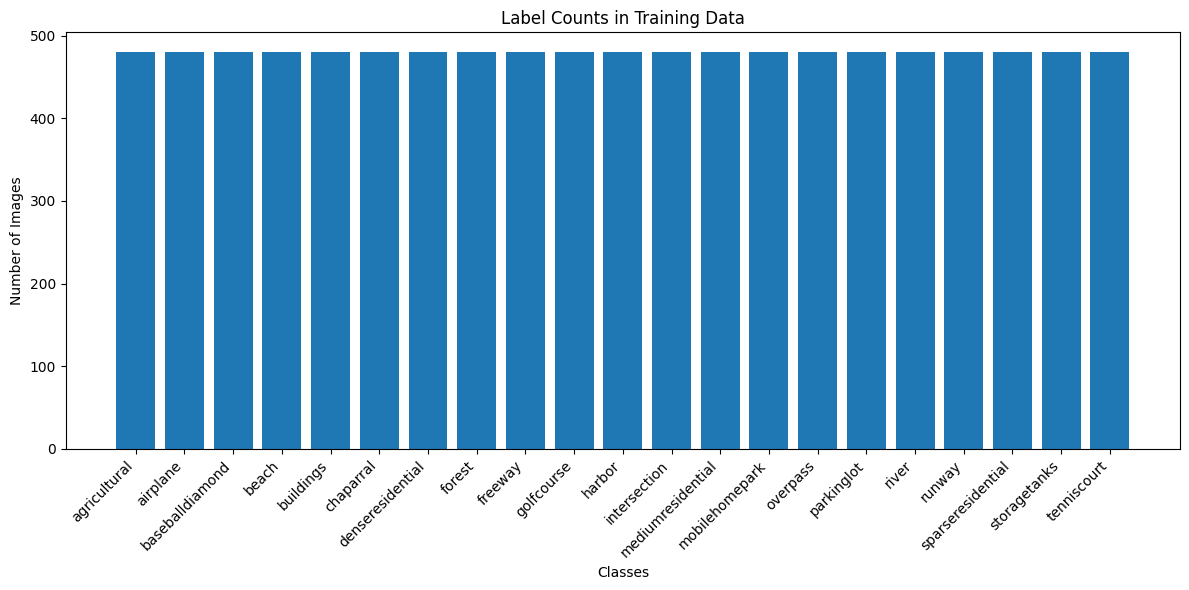

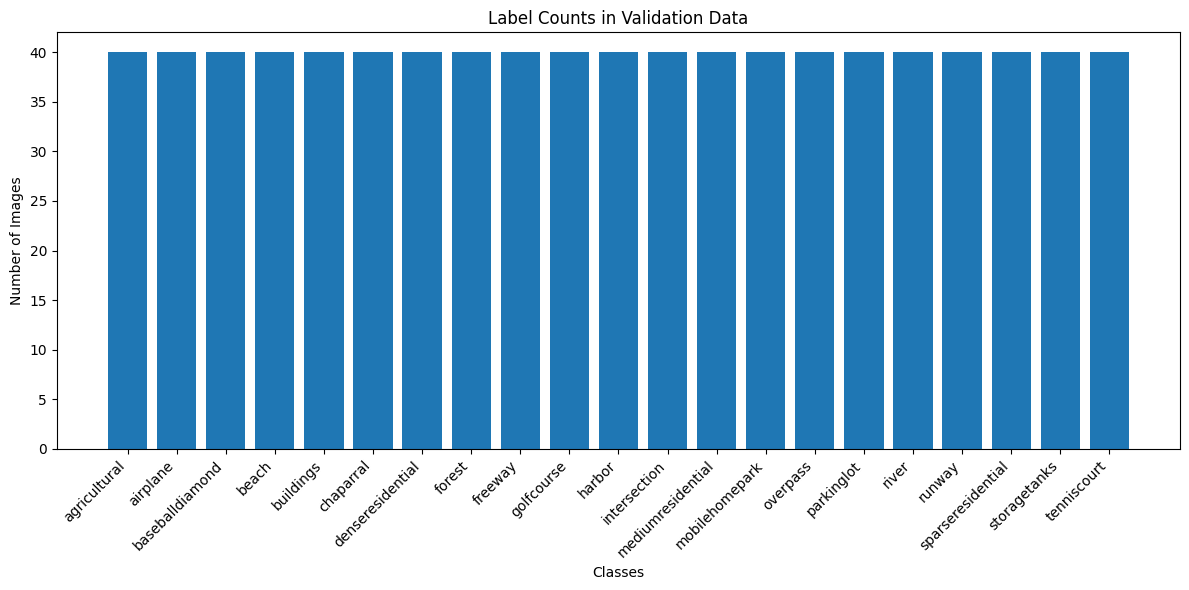

In [16]:
import os
import matplotlib.pyplot as plt

# Define the dataset paths
base_path = "UCMerced_LandUse"  # Replace with your base folder path
train_path = os.path.join(base_path, "train_augmented")
validation_path = os.path.join(base_path, "validation")

# Function to count labels in a given folder
def count_labels(folder_path):
    label_counts = {}
    for label in os.listdir(folder_path):
        label_path = os.path.join(folder_path, label)
        if os.path.isdir(label_path):
            images = [img for img in os.listdir(label_path) if img.endswith(('.png', '.jpg', '.jpeg', '.tif', '.tiff'))]
            label_counts[label] = len(images)
    return label_counts

# Function to plot label count chart
def plot_label_counts(label_counts, title):
    plt.figure(figsize=(12, 6))
    plt.bar(label_counts.keys(), label_counts.values())
    plt.xticks(rotation=45, ha="right")
    plt.title(title)
    plt.xlabel("Classes")
    plt.ylabel("Number of Images")
    plt.tight_layout()
    plt.show()

# Count labels in train and validation folders
train_label_counts = count_labels(train_path)
validation_label_counts = count_labels(validation_path)

# Plot label counts for train and validation
plot_label_counts(train_label_counts, "Label Counts in Training Data")
plot_label_counts(validation_label_counts, "Label Counts in Validation Data")
